**Discussion**

At some point, while testing the Elo rating system over a really large (unrealistic) number of games with skill based matchmaking, I found that the system was actually diverging from the true ratings after converging. I call this phenomenon "rating drift". This phenomenon is also present in Glicko and Glicko2, though the divergence is much slower. 

We can see when ratings are unbounded, the players ratings fan out seemingly infinitely from their initial point in a distribution similar to that of a "flattening normal" where the variance is increasing to infinity. A possible explanation for this observation is that because skill based matchmaking aims to have players of equal skill match up, the win rates of any player is close to 50% and they gain or lose an almost fixed amount of rating per match, thus every player's rating is essentially a binomial where n, the number of games played, is increasing so variance increases. By this idea, the speed of the drift can be described by the standard deviation of the binomial, which is $O(\sqrt{n})$. 

In the bounded ratings case, the players ratings also drift out, but since the ratings are bounded, they seem to converge to a uniform distribution. A possible explanation is that there is a result that states if a Markov chain is irreducible, aperiodic, finite, and has a doubly stochastic transition matrix, then it has a uniform stationary distribution. Then, if we consider a simplified Elo model where all players have the same true rating (so same win rates), and can only gain or lose a fixed amount of rating per match, then such a system does satisfy the above result. This simplified model is not so different from the actual Elo model with skill based matchmaking since skill based matchmaking explicitly tries to match players of similar visible rating and thus also implicitly matches players of similar true rating, so win rates are close to 50% and the rating changes per match are also close to fixed (since visible ratings are always close). 

Recently, after some discussion with Prof. Yanjun Han, he recommended that I look at this phenomenon from an online convex optimization perspective. The idea is that we know that the Elo rating system is analogous to stochastic gradient descent update with log loss, so when we introduce skill based matchmaking, we are essentially taking biased gradients for our updates since we only ever have matches between players of similar visible rating. These biased gradients cause the system to initially converge, but then diverge possibly because the noise of 50% coin flip matches dominates the gradient update. Another idea is that since skill based matchmaking only has access to local data, relative shifts in rating of the player pool will tend to stick rather than fix themselves. So for example, if a group of high true rated players unluckily lose multiple matches to collectively drop in visible rating, they will still match with each other for even games. 

I also looked into the regret of the Elo system under both random and skill based matchmaking, and they both seem to decrease in the same pattern. It's hard to say whether they do go to zero or not due to computation constraints, but when we don't gradually decrease the rating constant, the regret reaches a threshold where it starts to plateau. If we do gradually decrease the rating constant, then in both matchmaking schemes, the regret continually decreases.

In [125]:
import numpy as np
from elo import Elo
from glicko import Glicko
from glicko2 import Glicko2

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [126]:
num_players = 1000
init_rating = np.full(num_players, 1500, dtype=np.float32)
# init_true_rating = np.random.uniform(0, 3000, num_players).astype(np.float32)
# init_true_rating = np.random.rand(num_players).astype(np.float32) * 3000
init_true_rating = np.random.normal(1500, 350, num_players).astype(np.float32)
# init_true_rating = np.full(num_players, 1500)
# init_rating = np.copy(init_true_rating)

In [127]:
elo_sbm = Elo(num_players, init_rating, init_true_rating, rating_const=32)
elo_rm = Elo(num_players, init_rating, init_true_rating, rating_const=32)

In [128]:
losses_sbm = []
diffs_sbm = []
losses_rm = []
diffs_rm = []

for i in range(100000):
    loss, win_prob, diff = elo_sbm.match_all_realistic()
    losses_sbm.append(loss)
    diffs_sbm.append(diff)

    loss, win_prob, diff = elo_rm.match_all_random()
    losses_rm.append(loss)
    diffs_rm.append(diff)

    # decay rating constant so we get better convergence
    # if i%30000==0:
    #     elo_sbm.change_const(elo_sbm.rating_const / 2)
    #     elo_rm.change_const(elo_rm.rating_const / 2)



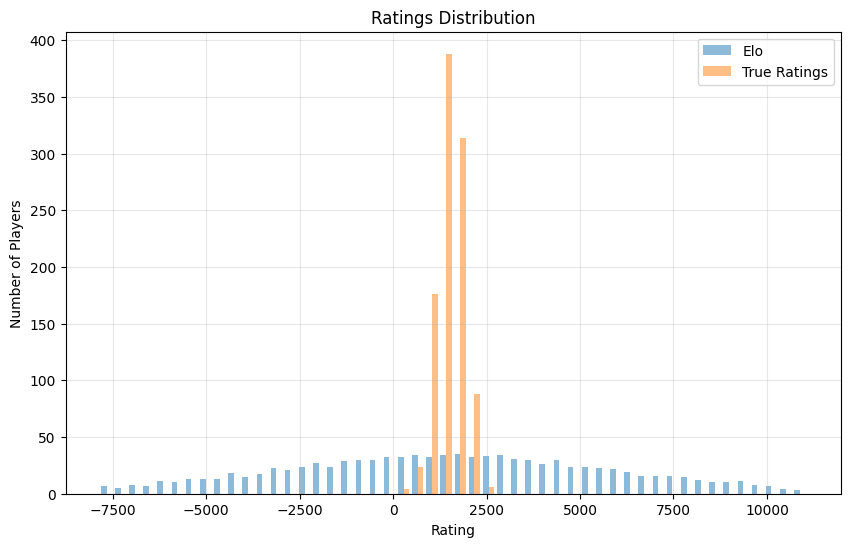

In [129]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist([elo_sbm.ratings, elo_sbm.true_ratings], bins=50, alpha=0.5, 
         label=["Elo", "True Ratings"])
plt.title("Ratings Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Players")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

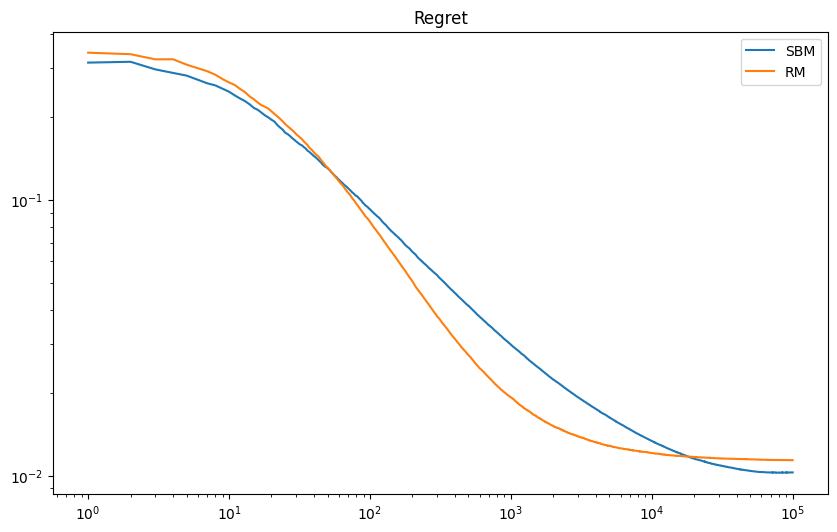

In [130]:
plt.figure(figsize=(10, 6))
x = np.arange(1, len(losses_sbm)+1)
plt.loglog(x, np.cumsum(losses_sbm) / x, label='SBM')
plt.loglog(x, np.cumsum(losses_rm) / x, label='RM')
plt.title("Regret")
# plt.plot(x, losses)

plt.legend()
plt.show()

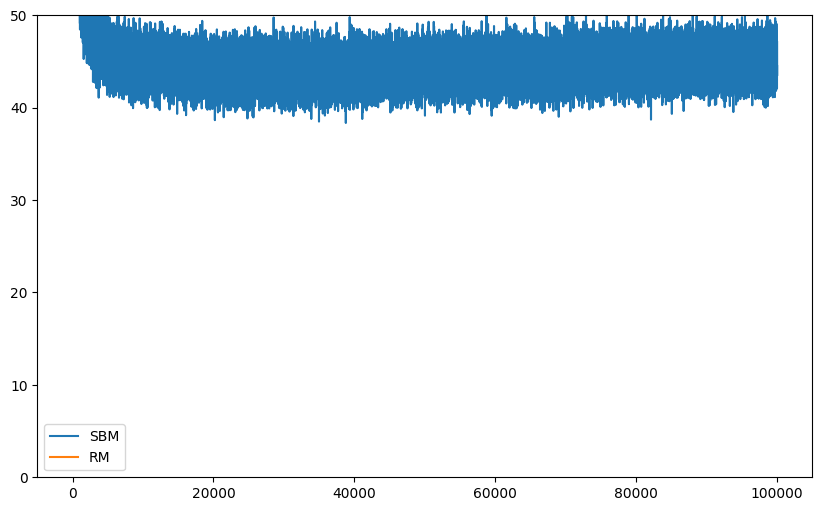

In [131]:
plt.figure(figsize=(10, 6))
x = np.arange(1, len(losses_sbm)+1)
plt.plot(x, diffs_sbm, label='SBM')
plt.plot(x, diffs_rm, label='RM')
plt.ylim(0, 50)
# plt.plot(x, losses)

plt.legend()
plt.show()

In [132]:
print((np.cumsum(losses_sbm) / x)[-1])

0.010287522701732969


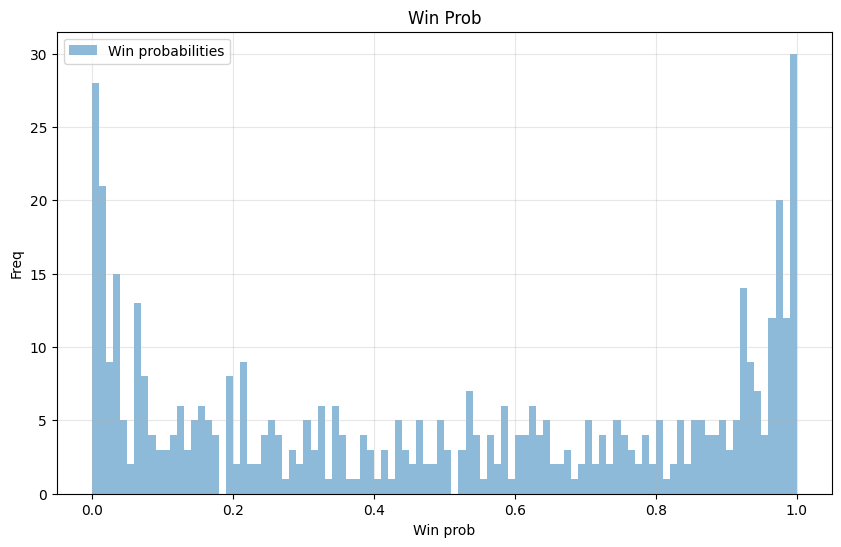

In [133]:
plt.figure(figsize=(10, 6))
plt.hist(win_prob, bins=100, alpha=0.5, 
         label="Win probabilities")
plt.title("Win Prob")
plt.xlabel("Win prob")
plt.ylabel("Freq")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [134]:
ratings = np.copy(elo_sbm.ratings)
true_ratings = np.copy(elo_sbm.true_ratings)

sorted_rating_indices = np.argsort(ratings)

id1, id2 = sorted_rating_indices[::2], sorted_rating_indices[1::2]

test = (true_ratings[id1] - true_ratings[id2]) - (ratings[id1] - ratings[id2])

# print(losses[-1])
print(np.mean(np.abs(test)))

from func import prob_log
win_prob = prob_log(true_ratings[id1], true_ratings[id2])

outcomes = np.random.rand(*np.shape(win_prob)) < win_prob

expected_outcomes = prob_log(ratings[id1], ratings[id2])

cross_entropy = -np.mean(
    outcomes * np.log(expected_outcomes) +
    (1 - outcomes) * np.log(1 - expected_outcomes)
)

true_loss = -np.mean(
    outcomes * np.log(win_prob) +
    (1 - outcomes) * np.log(1 - win_prob)
)
print(cross_entropy - true_loss)

24.674246
0.0019081942141057073


In [135]:
ratings = np.copy(elo_rm.ratings)
true_ratings = np.copy(elo_rm.true_ratings)

sorted_rating_indices = np.argsort(ratings)

id1, id2 = sorted_rating_indices[::2], sorted_rating_indices[1::2]

test = (true_ratings[id1] - true_ratings[id2]) - (ratings[id1] - ratings[id2])

# print(losses[-1])
print(np.mean(np.abs(test)))

from func import prob_log
win_prob = prob_log(true_ratings[id1], true_ratings[id2])

outcomes = np.random.rand(*np.shape(win_prob)) < win_prob

expected_outcomes = prob_log(ratings[id1], ratings[id2])

cross_entropy = -np.mean(
    outcomes * np.log(expected_outcomes) +
    (1 - outcomes) * np.log(1 - expected_outcomes)
)

true_loss = -np.mean(
    outcomes * np.log(win_prob) +
    (1 - outcomes) * np.log(1 - win_prob)
)
print(cross_entropy - true_loss)

59.20532
0.02373274171352391


In [136]:
num_players = 1000
init_rating = np.full(num_players, 1500, dtype=np.float32)
# init_true_rating = np.random.uniform(0, 3000, num_players).astype(np.float32)
# init_true_rating = np.random.rand(num_players).astype(np.float32) * 3000
init_true_rating = np.random.normal(1500, 350, num_players).astype(np.float32)
# init_true_rating = np.full(num_players, 1500)
# init_rating = np.copy(init_true_rating)

elo_sbm = Elo(num_players, init_rating, init_true_rating, rating_const=32)
elo_rm = Elo(num_players, init_rating, init_true_rating, rating_const=32)

losses_sbm = []
diffs_sbm = []
losses_rm = []
diffs_rm = []

for i in range(100000):
    loss, win_prob, diff = elo_sbm.match_all_realistic(bounded=True)
    losses_sbm.append(loss)
    diffs_sbm.append(diff)

    loss, win_prob, diff = elo_rm.match_all_random()
    losses_rm.append(loss)
    diffs_rm.append(diff)

    # decay rating constant so we get better convergence
    # if i%30000==0:
    #     elo_sbm.change_const(elo_sbm.rating_const / 2)
    #     elo_rm.change_const(elo_rm.rating_const / 2)


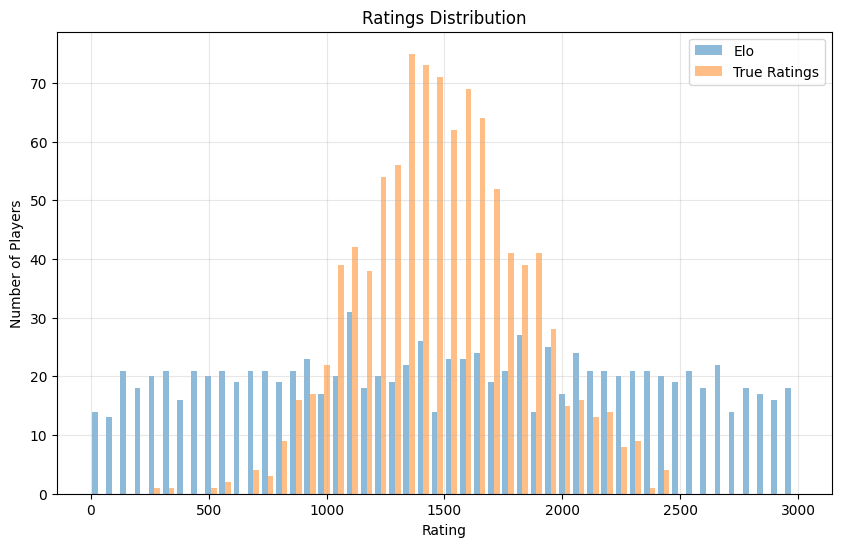

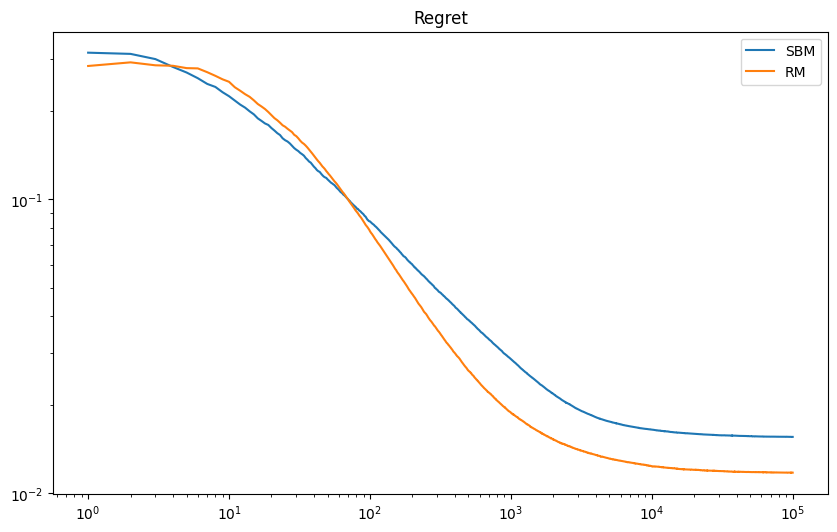

In [137]:
plt.figure(figsize=(10, 6))
plt.hist([elo_sbm.ratings, elo_sbm.true_ratings], bins=50, alpha=0.5, 
         label=["Elo", "True Ratings"])
plt.title("Ratings Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Players")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
x = np.arange(1, len(losses_sbm)+1)
plt.loglog(x, np.cumsum(losses_sbm) / x, label='SBM')
plt.loglog(x, np.cumsum(losses_rm) / x, label='RM')
plt.title("Regret")
# plt.plot(x, losses)

plt.legend()
plt.show()